   Order_ID Customer_ID  Customer_Age Customer_Gender    Customer_Segment  \
0  ORD00001    CUST0328            46           Other  Young Professional   
1  ORD00001    CUST0328            46           Other  Young Professional   
2  ORD00002    CUST0016            21          Female             Student   
3  ORD00002    CUST0016            21          Female             Student   
4  ORD00002    CUST0016            21          Female             Student   

  Loyalty_Member        Date  Year  Month  Day  ...      Storage_Type  \
0            Yes  2023-01-01  2023      1    1  ...      Refrigerated   
1            Yes  2023-01-01  2023      1    1  ...       Dry Storage   
2             No  2023-01-01  2023      1    1  ...      Refrigerated   
3             No  2023-01-01  2023      1    1  ...       Dry Storage   
4             No  2023-01-01  2023      1    1  ...  Room Temperature   

  Perishability  Store_ID Units_Produced Units_Sold Unsold_Units  \
0     Very High      ST02     

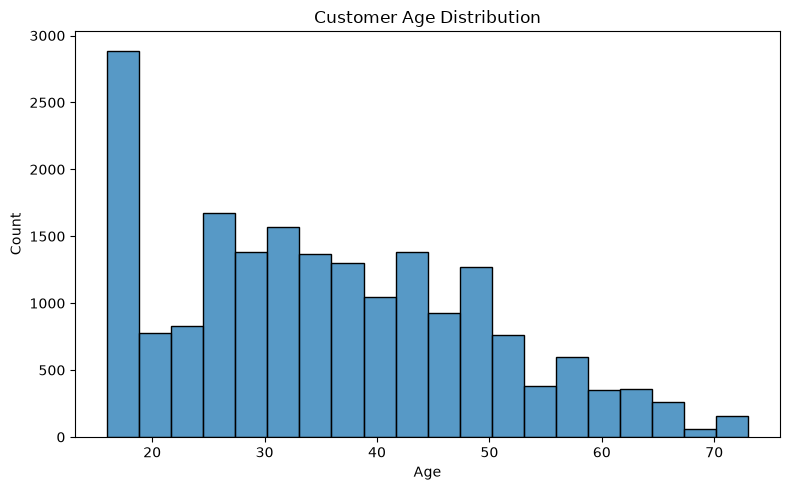

Age_Group
65+      56.250000
26-35    46.491718
56-65    45.952024
<18      44.969644
46-55    40.433333
36-45    39.695032
18-25    31.818182
Name: Loyalty_Member, dtype: float64


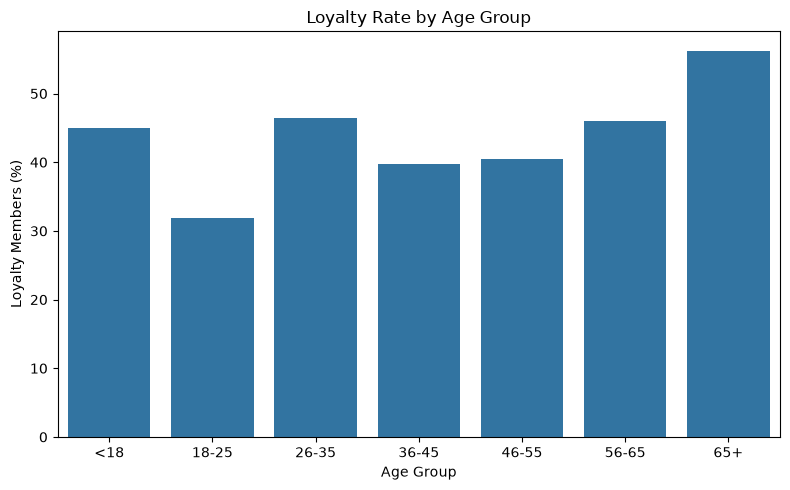

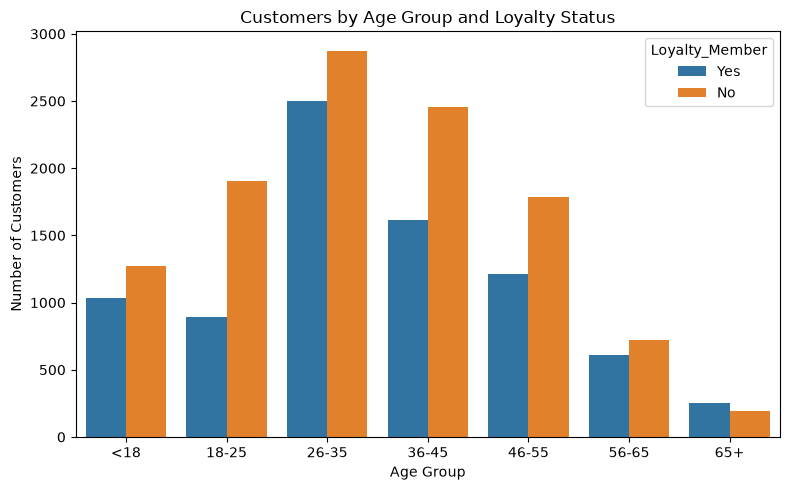

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
#loading of data 
data = pd.read_csv("bakery_sales_dataset.csv")



print(data.head())

# Data Cleaning and finding missing values
print(data.isnull().sum())
print(f"Festival missing: {data['Festival'].isna().mean() * 100:.1f}%")
data["Festival"] = data["Festival"].fillna("No Festival")

# Duplicates
print("Duplicates:", data.duplicated().sum())
data = data.drop_duplicates()

# Age distribution
plt.figure(figsize=(8, 5))
sns.histplot(data["Customer_Age"], bins=20)
plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.tight_layout()
plt.show()

# Age groups
data["Age_Group"] = pd.cut(
    data["Customer_Age"],
    bins=[0, 18, 26, 36, 46, 56, 66, 120],
    labels=["<18", "18-25", "26-35", "36-45", "46-55", "56-65", "65+"],
    right=False,
)

# Loyalty rate by age group
loyalty_rate = (
    data.groupby("Age_Group", observed=True)["Loyalty_Member"]
    .apply(lambda x: (x == "Yes").mean() * 100)
)
print(loyalty_rate.sort_values(ascending=False))

plt.figure(figsize=(8, 5))
sns.barplot(x=loyalty_rate.index, y=loyalty_rate.values)
plt.xlabel("Age Group")
plt.ylabel("Loyalty Members (%)")
plt.title("Loyalty Rate by Age Group")
plt.tight_layout()
plt.show()

# Customer count by age group and loyalty
plt.figure(figsize=(8, 5))
sns.countplot(data=data, x="Age_Group", hue="Loyalty_Member")
plt.title("Customers by Age Group and Loyalty Status")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()